In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("integrated_hospitals.csv")
print(df.shape)
print(df.head())

(5419, 40)
  Facility ID                    Facility Name                     Address  \
0      010001  SOUTHEAST HEALTH MEDICAL CENTER      1108 ROSS CLARK CIRCLE   
1      010005         MARSHALL MEDICAL CENTERS  2505 U S HIGHWAY 431 NORTH   
2      010007         MIZELL MEMORIAL HOSPITAL               702 N MAIN ST   
3      010011               ST. VINCENT'S EAST  50 MEDICAL PARK EAST DRIVE   
4      010012   DEKALB REGIONAL MEDICAL CENTER        200 MED CENTER DRIVE   

    City/Town State  ZIP Code         Hospital Type  \
0      DOTHAN    AL     36301  Acute Care Hospitals   
1        BOAZ    AL     35957  Acute Care Hospitals   
2         OPP    AL     36467  Acute Care Hospitals   
3  BIRMINGHAM    AL     35235  Acute Care Hospitals   
4  FORT PAYNE    AL     35968  Acute Care Hospitals   

                            Hospital Ownership  Hospital overall rating  \
0  Government - Hospital District or Authority                      4.0   
1  Government - Hospital District or Au

In [19]:
df.dtypes

Facility ID                   object
Facility Name                 object
Address                       object
City/Town                     object
State                         object
ZIP Code                       int64
Hospital Type                 object
Hospital Ownership            object
Hospital overall rating      float64
H_CLEAN_LINEAR_SCORE         float64
H_COMP_1_LINEAR_SCORE        float64
H_COMP_2_LINEAR_SCORE        float64
H_COMP_3_LINEAR_SCORE        float64
H_COMP_5_LINEAR_SCORE        float64
H_COMP_6_LINEAR_SCORE        float64
H_COMP_8_LINEAR_SCORE        float64
H_COMP_9_LINEAR_SCORE        float64
H_HSP_RATING_LINEAR_SCORE    float64
H_RECMND_LINEAR_SCORE        float64
H_SYMP_LINEAR_SCORE          float64
COMP_HIP_KNEE                float64
Hybrid_HWM                   float64
ISCMR                        float64
MORT_30_AMI                  float64
MORT_30_CABG                 float64
MORT_30_COPD                 float64
MORT_30_HF                   float64
M

In [20]:
print(df[df.columns].describe())

           ZIP Code  Hospital overall rating  H_CLEAN_LINEAR_SCORE  \
count   5419.000000              3174.000000           3181.000000   
mean   53847.149843                 3.206994             86.513675   
std    27048.532955                 1.094208              4.395919   
min      603.000000                 1.000000             68.000000   
25%    32796.000000                 2.000000             84.000000   
50%    55103.000000                 3.000000             87.000000   
75%    76112.500000                 4.000000             90.000000   
max    99929.000000                 5.000000             99.000000   

       H_COMP_1_LINEAR_SCORE  H_COMP_2_LINEAR_SCORE  H_COMP_3_LINEAR_SCORE  \
count             3181.00000            3181.000000            3181.000000   
mean                91.28796              90.618673              82.657026   
std                  2.57554               2.643757               4.908368   
min                 76.00000              76.000000      

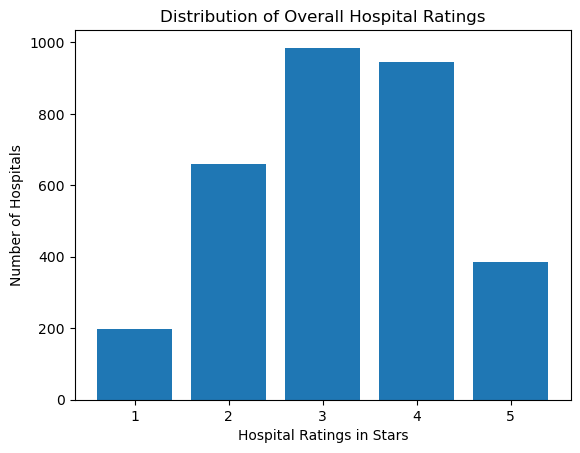

In [21]:
ratings = df['Hospital overall rating'].value_counts().sort_index()

plt.bar(ratings.index, ratings.values)
plt.title('Distribution of Overall Hospital Ratings')
plt.xlabel('Hospital Ratings in Stars')
plt.ylabel('Number of Hospitals')
plt.xticks([1,2,3,4,5])
plt.show()

In [22]:
print(df["Hospital overall rating"].isna().sum())

2245


The distribution of the overall hopsital ratings displays that the majority of available hospitals recieve ratings of 3 or 4 stars, while the fewest frequencies belong to those of 1 and 5 stars. These findings suggest that hospital ratings tend to be concentrated toward the middle and upper portions of the five-star scale. However, a significant number of hospitals, about 41.4% of all entries, do not have overall ratings. They were excluded from this visulization and it should be noted how much data is missing from this graph.  

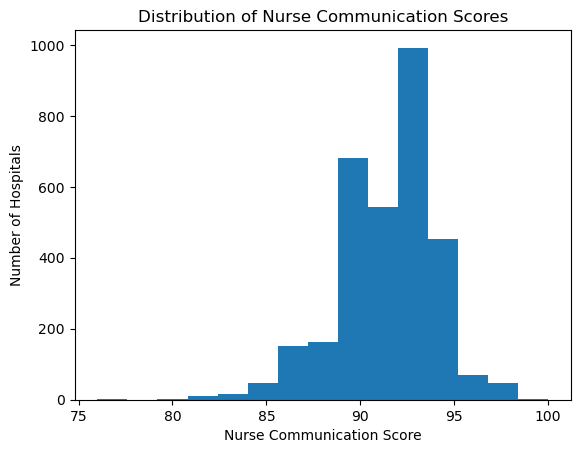

In [23]:
plt.hist(df['H_COMP_1_LINEAR_SCORE'].dropna(),
         bins = 15)
plt.title('Distribution of Nurse Communication Scores')
plt.xlabel('Nurse Communication Score')
plt.ylabel('Number of Hospitals')

plt.show()

The distribution of nurse communication scores shows that the majority of hospitals have a relatively high patient experience scores, mostly falling within the range of 90 and 95, close to the mean at 91.28. The distribution is slightly skewed to the left, meaning that nurse communications are generally rated on the higher end, there are some hospitals with considerably lower scores demonstrating variability across the dataset. 

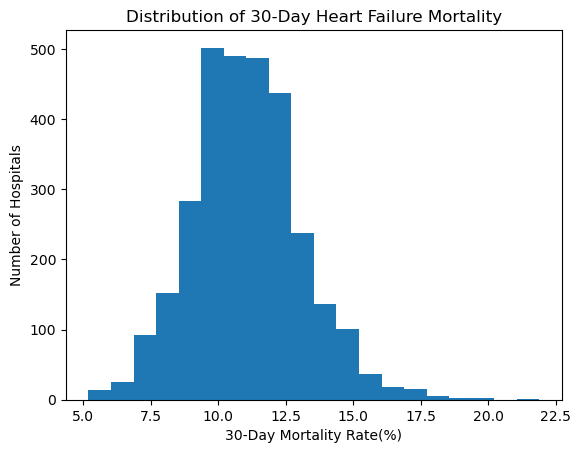

In [24]:
plt.hist(df['MORT_30_HF'].dropna(),
         bins = 20)

plt.title('Distribution of 30-Day Heart Failure Mortality')
plt.xlabel('30-Day Mortality Rate(%)')
plt.ylabel('Number of Hospitals')
plt.show()

The average reported 30-day heart failure mortality measure rate is 11.07%, and the distribution supports this by showing that the majority of the hospitals have reported mortality rates between about 9% and 13%. It is roughly bell-shaped with the slightest skew to the right which means that while most hospitals fall between a narrow range of mortality rates, there are a small number of hospitals that have considerably higher mortality rates.  

These preliminary visualizations provide a foundation for further analysis. Our next steps include examining correlations, comparing additional patient experience and clinical outcome measures, and evaluating the effects of missing values. We will also consider differences in reporting periods and avoid interpreting observed associations as causal relationships.